In [1]:
from IPython.core.debugger import set_trace

# Import Generic Classes
import numpy as np
import copy
import pickle
import random

# Import All Custom Classes
import os, sys
sys.path.append(os.path.pardir+"/classes")
sys.path.append(os.path.pardir+"/solvers")
sys.path.append(os.path.pardir+"/one_mobility")
sys.path.append(os.path.curdir + "/sim_store/sim20")
sys.path.append(os.path.curdir + "/sim_store/sim23")
sys.path.append(os.path.pardir+"/crawdad_mobility")


from Server import *
from User import *
from Link import *
from Job import *
from Migration_Plans import *
from Cost_Recordings import *

from sim23_setting import *
from load_crawdad_usr import *
from sub_costs import *


# Import Solver Classes
from Optim_PlanGenerator import *
from SeqGreedy_PlanGenerator import *
from Myopic_PlanGenerator import *
from Naive_PlanGenerator import *
from Cloud_PlanGenerator import *

In [2]:
# Load Crawdad data
# Load All 12 users and trim their info
db_names = []
for i in range(1,13):
    if i != 8 and i != 12:
        db_names += ['LifeMap_GS'+str(i)+'.db']

db = []
for name in db_names:
    print(name)
    name = os.path.pardir+ "/crawdad_mobility/" + name
    df,trace = load_usr(name)
    db += [trace]

LifeMap_GS1.db
LifeMap_GS2.db
LifeMap_GS3.db
LifeMap_GS4.db
LifeMap_GS5.db
LifeMap_GS6.db
LifeMap_GS7.db
LifeMap_GS9.db
LifeMap_GS10.db
LifeMap_GS11.db


In [3]:
# num_user by type
num_users_list = [[0,0,0,20],[0,0,20,0]]


In [4]:
num_trials = 5
key = "mig_rate"

for k in range(len(num_users_list)):
    Batch_cost_stores = []
    SG_cost_stores = []
    Naive_cost_stores = []
    Myopic_cost_stores = []
    Cloud_cost_stores = []
    
    Batch_mig_stores = []
    SG_mig_stores = []
    Naive_mig_stores = []
    Myopic_mig_stores = []
    Cloud_mig_stores = []

    for i in range(num_trials):

        print("Trial Number:",i, "user_count:", np.sum(num_users_list[k]))

#         print("limited")
#         users, servers, links, jobs, sim_param = simulation_setting(num_users_list[k], db)

        while True:
            try:
                users, servers, links, jobs, sim_param = simulation_setting(num_users_list[k], db)
                Batch_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs, sim_param)
                Batch_plan = Migration_Plans(users,jobs,sim_param)
                Batch_plan.from_seq_greedy(Batch_prob)
                Batch_cost_stores += [Cost_Recordings(Batch_plan)]
                break
            except:
                print("batch_broken, repeating with new users")
                continue
                
        num_mig_cumul = 0
        for u in range(len(jobs)):
            num_mig_cumul += np.sum(Batch_plan.mig_plan_dict[u][key])
        Batch_mig_stores += [num_mig_cumul]


        # Make SG Prob
        # Set Refresh to false for SG
        refresh_rate = [0,0]
        refresh = False

        jobs2 = copy.deepcopy(jobs)
        for j in range(len(jobs2)):
            jobs2[j].info_from_usr(users[j],refresh_rate,refresh)

        # print("SG prob...")
        SG_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs2, sim_param)
        SG_plan = Migration_Plans(users,jobs2,sim_param)
        SG_plan.from_seq_greedy(SG_prob)
        SG_cost_stores += [Cost_Recordings(SG_plan)]
        # print("done!")
        num_mig_cumul = 0
        for u in range(len(jobs)):
            num_mig_cumul += np.sum(SG_plan.mig_plan_dict[u][key])
        SG_mig_stores += [num_mig_cumul]

        # Make Cloud Prob
        # print("Cloud prob...")
        Cloud_prob = Cloud_PlanGenerator(users, servers, links, jobs, sim_param)
        Cloud_plan = Migration_Plans(users,jobs,sim_param)
        Cloud_plan.from_seq_greedy(Cloud_prob)
        Cloud_cost_stores += [Cost_Recordings(Cloud_plan)]
        # print("done!")
        num_mig_cumul = 0
        for u in range(len(jobs)):
            num_mig_cumul += np.sum(Cloud_plan.mig_plan_dict[u][key])
        Cloud_mig_stores += [num_mig_cumul]

        # Make Naive Prob
        # print("Naive prob...")
        Naive_prob = Naive_PlanGenerator(users, servers, links, jobs, sim_param)
        Naive_plan = Migration_Plans(users,jobs,sim_param)
        Naive_plan.from_seq_greedy(Naive_prob)
        Naive_cost_stores += [Cost_Recordings(Naive_plan)]
        # print("done!")
        num_mig_cumul = 0
        Naive_mig_stores += [num_mig_cumul]

        # Make Myopic Prob
        # print("Myopic prob...")
        Myopic_prob = Myopic_PlanGenerator(users, servers, links, jobs, sim_param)
        Myopic_plan = Migration_Plans(users,jobs,sim_param)
        Myopic_plan.from_seq_greedy(Myopic_prob)
        Myopic_cost_stores += [Cost_Recordings(Myopic_plan)]
        # print("done!")
        num_mig_cumul = 0
        for u in range(len(jobs)):
            num_mig_cumul += np.sum(Myopic_plan.mig_plan_dict[u][key])
        Myopic_mig_stores += [num_mig_cumul]

        
    cost_stores_dic = {}
    cost_stores_dic["SG"] = SG_cost_stores
    cost_stores_dic["Batch"] = Batch_cost_stores
    cost_stores_dic["Naive"] = Naive_cost_stores
    cost_stores_dic["Myopic"] = Myopic_cost_stores
    cost_stores_dic["Cloud"] = Cloud_cost_stores

    pickle.dump(cost_stores_dic, open(os.path.curdir + "/sim_store/sim23/n2_cost_store_u"+ str(k) +".p", "wb" ) )

    
    mig_stores_dict = {}
    mig_stores_dict['SG'] = SG_mig_stores
    mig_stores_dict['Batch'] = Batch_mig_stores
    mig_stores_dict['Naive'] = Naive_mig_stores
    mig_stores_dict['Myopic'] = Myopic_mig_stores
    mig_stores_dict['Cloud'] = Cloud_mig_stores
    pickle.dump(mig_stores_dict, open(os.path.curdir + "/sim_store/sim23/n2_mig_store_u"+ str(k) +".p", "wb" ) )

    

Trial Number: 0 user_count: 20
Trial Number: 1 user_count: 20
Trial Number: 2 user_count: 20
Trial Number: 3 user_count: 20
Trial Number: 4 user_count: 20
Trial Number: 0 user_count: 20
Trial Number: 1 user_count: 20
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
Trial Number: 2 user_count: 20
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
Trial Number: 3 user_count: 20
not enough resources, simulation broken
batch_broken, repeating with new users
not enough resources, simulation broken
batch_broken, repeating with new users
not enough

### Make figures with cost
1. User Density vs. Total Cost per User
2. User Density vs. Latency Cost per User

In [5]:
latencies_SG = []
latencies_Batch = []
latencies_Myopic = []
latencies_Cloud = []
latencies_Naive = []

total_costs_SG = []
total_costs_Batch = []
total_costs_Myopic = []
total_costs_Cloud = []
total_costs_Naive = []

latencies_SG_var = []
latencies_Batch_var = []
latencies_Myopic_var = []
latencies_Cloud_var = []
latencies_Naive_var = []

total_costs_SG_var = []
total_costs_Batch_var = []
total_costs_Myopic_var = []
total_costs_Cloud_var = []
total_costs_Naive_var = []

for i in range(len(num_users_list)):
    # open a file, where you stored the pickled data
    total_users = np.sum(num_users_list[i])
    name = "/sim_store/sim23/n2_cost_store_u"+ str(i) +".p"
    file = open(os.path.curdir + name, 'rb')

    # dump information to that file
    data = pickle.load(file)

    SG_cost, Batch_cost, Myopic_cost, Naive_cost, Cloud_cost = obtain_sub_costs(data)
    latencies_SG += [SG_cost[3]/total_users]
    latencies_Batch += [Batch_cost[3]/total_users]
    latencies_Myopic += [Myopic_cost[3]/total_users]
    latencies_Cloud += [Cloud_cost[3]/total_users]
    latencies_Naive += [Naive_cost[3]/total_users]
    
    total_costs_SG += [SG_cost[0]/total_users]
    total_costs_Batch += [Batch_cost[0]/total_users]
    total_costs_Myopic += [Myopic_cost[0]/total_users]
    total_costs_Cloud += [Cloud_cost[0]/total_users]
    total_costs_Naive += [Naive_cost[0]/total_users]
    
    cost_var, lat_var = obtain_sub_vars(data)
    
    latencies_SG_var += [lat_var['SG']/total_users]
    latencies_Batch_var += [lat_var['Batch']/total_users]
    latencies_Myopic_var += [lat_var['Myopic']/total_users]
    latencies_Cloud_var += [lat_var['Cloud']/total_users]
    latencies_Naive_var += [lat_var['Naive']/total_users]

    total_costs_SG_var += [cost_var['SG']/total_users]
    total_costs_Batch_var += [cost_var['Batch']/total_users]
    total_costs_Myopic_var += [cost_var['Myopic']/total_users]
    total_costs_Cloud_var += [cost_var['Cloud']/total_users]
    total_costs_Naive_var += [cost_var['Naive']/total_users]
    
    name2 = "/sim_store/sim23/n2_mig_store_u"+ str(i) +".p"
    file = open(os.path.curdir + name, 'rb')


In [15]:
#SG
5.6268919056782405/3.028235203879441

1.858142293065508

In [16]:
# Batch
3.4707796312800747/3.028235203879441

1.1461393840325529

In [18]:
# Cloud
6.33629300/4.160361258963361

1.5230150954676511

In [6]:
print("SG total cost:", total_costs_SG)
print("Bt total cost:", total_costs_Batch)
print("My total cost:", total_costs_Myopic)
print("Cl total cost:", total_costs_Cloud)
print("Na total cost:", total_costs_Naive)

print("SG total var:", total_costs_SG_var)
print("Bt total var:", total_costs_Batch_var)
print("My total var:", total_costs_Myopic_var)
print("Cl total var:", total_costs_Cloud_var)
print("Na total var:", total_costs_Naive_var)


SG total cost: [3.028235203879441, 5.6268919056782405]
Bt total cost: [3.028235203879441, 3.4707796312800747]
My total cost: [5.05363911298924, 4.470327233171177]
Cl total cost: [4.160361258963361, 6.336293005314845]
Na total cost: [8.053805558066985, 8.105266739207078]
SG total var: [0.18842393294452817, 0.9445542574135114]
Bt total var: [0.18842393294452817, 0.29408168131989443]
My total var: [0.3512802371751765, 0.49956045427593676]
Cl total var: [0.4956141855641832, 1.02824458688638]
Na total var: [0.5457499947730546, 0.6877159594549316]


In [10]:
total_costs_SG

[3.028235203879441, 5.6268919056782405]

/home/tkim/anaconda3/lib/python3.7/site-packages/matplotlib/font_manager.py:1331: UserWarning: findfont: Font family ['normal'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


<Figure size 432x288 with 0 Axes>

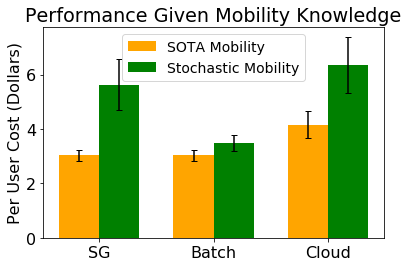

In [17]:
# Collect the correct costs
# Plot the plot
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 16}

matplotlib.rc('font', **font)
#figure(num=None, figsize=(5.5, 2.5), dpi=80, facecolor='w', edgecolor='k')
figure()
x_ax = [0,1]
labels = ['SG', 'Batch', 'Cloud']

deterministic_y = [total_costs_SG[0], total_costs_Batch[0], total_costs_Cloud[0]]
stochastic_y = [total_costs_SG[1], total_costs_Batch[1], total_costs_Cloud[1]]

deterministic_y_var = [total_costs_SG_var[0], total_costs_Batch_var[0],total_costs_Cloud_var[0]]
stochastic_y_var = [total_costs_SG_var[1], total_costs_Batch_var[1],total_costs_Cloud_var[1]]

x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x = x-width/2, height =  deterministic_y, yerr = deterministic_y_var,
                capsize = 3, width = width, label='SOTA Mobility', color='orange')
rects2 = ax.bar(x = x+width/2, height = stochastic_y, yerr = stochastic_y_var, 
                capsize = 3, width = width, label='Stochastic Mobility', color = 'green')


# Add some text for labels, title and custom x-axis tick labels, etc.
#ax.set_xlabel('Plan Type')
ax.set_ylabel('Per User Cost (Dollars)')
ax.set_title('Performance Given Mobility Knowledge')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend(loc = 'best', prop={'size': 14})# plt.ylim(0,)

# Set Y axis to zero
plt.ylim(0,)

fig.tight_layout()

plt.show()